# Initialize environment

In [1]:
try:
   import cPickle as pickle
except:
   import pickle

In [2]:
import ipyparallel as ipp
import os
import time

c = ipp.Client()

Waiting for connection file: ~/.ipython/profile_default/security/ipcontroller-client.json


OSError: Connection file '~/.ipython/profile_default/security/ipcontroller-client.json' not found.
You have attempted to connect to an IPython Cluster but no Controller could be found.
Please double-check your configuration and ensure that a cluster is running.

In [ ]:
import ipyparallel as ipp
import os
import time

c = ipp.Client()
c[:].use_cloudpickle()
v = c.load_balanced_view()
v.map(os.chdir, [os.getcwd()]*len(c.ids))

In [ ]:
scenario_name = 'base'

In [ ]:
%matplotlib inline
%reload_ext autoreload
%load_ext line_profiler
%run -i deg
%run -i deg_params
%aimport ws3
%aimport deg
%autoreload 2

In [ ]:
twopass_cacut_factor = 1.50
run_sda = True
basenames = ['tsa30', 'tsa31']
#basenames = ['tsa05', 'tsa10', 'tsa15', 'tsa22', 'tsa27', 'tsa29', 'tsa30', 'tsa37']

In [ ]:
kwargs = []
for i, bn in enumerate(basenames):
    kwargs.append({'basenames':[bn],
                   'model_name':'%s_%s' % (scenario_name, bn),
                   'model_path':dat_path,
                   'yld_path':yld_path,
                   'tif_path':tif_path,
                   'horizon':horizon,
                   'period_length':period_length,
                   'max_age':max_age,
                   'basecodes':compile_basecodes({bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb'))}, [bn], theme_cols),
                   'action_params':action_params,
                   'hdt':{bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb'))},
                   'add_null_action':True,
                   'tvy_name':tvy_name,
                   'compile_actions':True,
                   'compile_ogi':True if scenario_name in ['rogh'] else False,
                   'verbose':1,
                   'scenario_name':scenario_name, 
                   'util':util, 
                   'deg_mode':deg_mode,
                   'fm_horizon':fm_horizon,
                   'sda_mode':sda_mode,
                   'obj_mode':obj_mode,
                   'base_year':base_year,
                   'run_sda':run_sda,
                   'cmp_fm_only':False,
                   'twopass_cacut_factor':twopass_cacut_factor,
                   'shp_path':shp_path,
                   'hdt_path':hdt_path,
                   'theme_cols':theme_cols,
                   'age_col':age_col})

# Testing mode (single TSA, interactive)

In [ ]:
enable_testing_mode = 1
test_i = 0 
if enable_testing_mode:
    print('testing model in interactive mode for:', kwargs[test_i]['basenames'][0])
    result = do_the_thing(**kwargs[test_i])

# Run DEG

This will launch the DEG in batch mode, running up to 16 TSA subproblems in parallel if multiple cores available and IPython cluster started correctly. 

In [12]:
amr = v.map_async(lambda kwargs: do_the_thing(**kwargs), kwargs)

In [ ]:
amr.wait_interactive()

   0/2 tasks finished after  265 s

# Reports and diagnostic output (optional)

The following chunk of code compiles a volume harvested report (CSV), which sums harvest volume in the aspatial wood supply models (by TSA). Note: this is based on the area scheduled for harvest in each period in the ws3 model, which will probably not exactly match the sum of pixels disturbed in a given period (post-SDA).  

In [22]:
import os
command_string = 'cp ~/notebooks/pics/dat/out/%s_*.* ~/notebooks/pics/dat/out/%s/' % (scenario_name, scenario_name)
#print(command_string)
command_result = os.system(command_string)

In [23]:
amr_fm = [unpickle_forestmodel(scenario_name, bn) for bn in basenames]

In [24]:
amr_sch = [unpickle_schedule(scenario_name, bn) for bn in basenames]

In [17]:
outfile = open('../dat/out/%s/%s_distout_vcut.csv' % (scenario_name, scenario_name), 'w')
outfile.write('SCENARIO,TSA,PERIOD,VCUT,ABRN\n')
for i, bn in enumerate(basenames[:]):
    print('compiling vcut report data for:', bn)
    fm, sch = amr_fm[i], amr_sch[i]
    fm.reset_actions()
    fm.initialize_areas()
    fm.apply_schedule(sch, compile_c_ycomps=True)
    for j in range(1, horizon+1):
        vcut = fm.compile_product(j, 'totvol * %0.2f' % util, acode='harvest')
        abrn = fm.compile_product(j, '1.', acode='fire')
        outfile.write('%s,%s,%i,%i,%i\n' % (scenario_name, bn, j, int(vcut), int(abrn)))
outfile.close()

compiling vcut report data for: tsa01
compiling vcut report data for: tsa02
compiling vcut report data for: tsa03
compiling vcut report data for: tsa04
compiling vcut report data for: tsa05
compiling vcut report data for: tsa07
compiling vcut report data for: tsa08
compiling vcut report data for: tsa09
compiling vcut report data for: tsa10
compiling vcut report data for: tsa11
compiling vcut report data for: tsa12
compiling vcut report data for: tsa13
compiling vcut report data for: tsa14
compiling vcut report data for: tsa15
compiling vcut report data for: tsa16
compiling vcut report data for: tsa17
compiling vcut report data for: tsa18
compiling vcut report data for: tsa19
compiling vcut report data for: tsa20
compiling vcut report data for: tsa21
compiling vcut report data for: tsa22
compiling vcut report data for: tsa23
compiling vcut report data for: tsa24
compiling vcut report data for: tsa25
compiling vcut report data for: tsa26
compiling vcut report data for: tsa27
compiling vc

The following chunk of code compiles an area disturbed report (CSV), which simply sums disturbed pixel counts in all DEG output GeoTIFF files, for all scenarios in `scenarionames`. Assumes user has copied output from each scenario to `../dat/out/SCENARIO_NAME/` (user responsible for creating scenario folders and copying files).

In [18]:
import zipfile
scenarionames = ['base'] #, 'more', 'rogh']
outfile = open('../dat/out/%s/%s_distout_area.csv' % (scenario_name, scenario_name), 'w')
outfile.write('SCENARIO,TSA,DISTURB,YEAR,AREA\n')
for sn in scenarionames:
    for bn in basenames[:]:
        print('compiling area report data for: scenario %s, %s' % (scenario_name, bn))
        with zipfile.ZipFile('../dat/out/%s/%s_%s_distout.zip' % (sn, sn, bn), 'r') as zf:
            zf.extractall('../dat/out/tmp')
        for dn in ['fire', 'harvest', 'slashburn']:
            for dy in range(60):
                yr = 2015 + dy
                with rasterio.open('../dat/out/tmp/%s/projected_%s_%i.tif' % (bn, dn, yr)) as src:
                    n = src.read()[0].sum()
                #print(sn, bn, dn, yr, n)
                outfile.write('%s,%s,%s,%i,%i\n' % (sn, bn, dn, yr, n))
outfile.close()                                

compiling area report data for: scenario base, tsa01
compiling area report data for: scenario base, tsa02
compiling area report data for: scenario base, tsa03
compiling area report data for: scenario base, tsa04
compiling area report data for: scenario base, tsa05
compiling area report data for: scenario base, tsa07
compiling area report data for: scenario base, tsa08
compiling area report data for: scenario base, tsa09
compiling area report data for: scenario base, tsa10
compiling area report data for: scenario base, tsa11
compiling area report data for: scenario base, tsa12
compiling area report data for: scenario base, tsa13
compiling area report data for: scenario base, tsa14
compiling area report data for: scenario base, tsa15
compiling area report data for: scenario base, tsa16
compiling area report data for: scenario base, tsa17
compiling area report data for: scenario base, tsa18
compiling area report data for: scenario base, tsa19
compiling area report data for: scenario base,

The following chunk of code runs some diagnostic functions on each TSA. For each TSA, the functions output harvest area in the schedule versus what was simulated (table and graphic), fire area, harvest volume, and some figures showing year-wise disaggregation of harvest and fire area targets in teh SDA step, and relative disaggregation error.

0 tsa05
   acut_sch  acut_ws3   fire  harvest  unit_hvol
t                                               
1     21005     21005  10438  5123809        243
2     19151     19151  10438  4647257        242
3     17601     17601  10439  4405694        250
4     16786     16786  10439  4409455        262
5     16050     16050  10439  4381457        272
6     14478     14478  10438  4387463        303
262.0
1 tsa10
   acut_sch  acut_ws3  fire  harvest  unit_hvol
t                                              
1      6200      6200   263  4205688        678
2      5909      5909   262  3790000        641
3      5615      5615   263  3634140        647
4      5353      5353   263  3614440        675
5      5322      5322   263  3613500        678
6      5325      5325   263  3614459        678
666.166666667
2 tsa15
   acut_sch  acut_ws3   fire  harvest  unit_hvol
t                                               
1     21003     21003  24057  4139624        197
2     20446     20446  24057  371

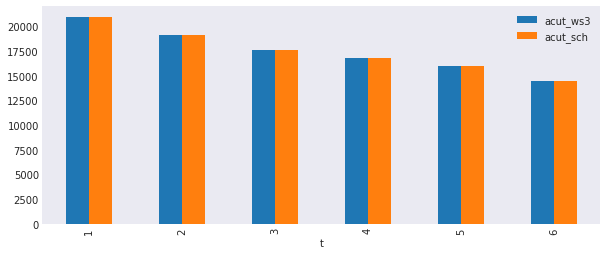

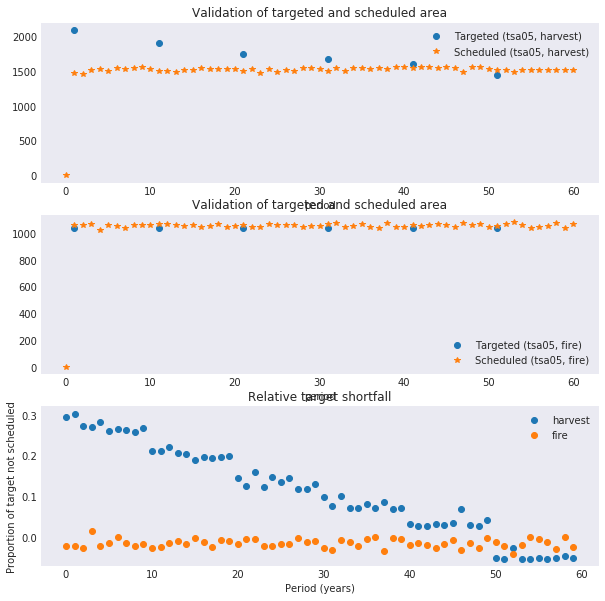

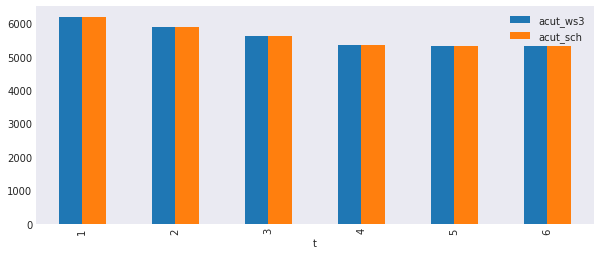

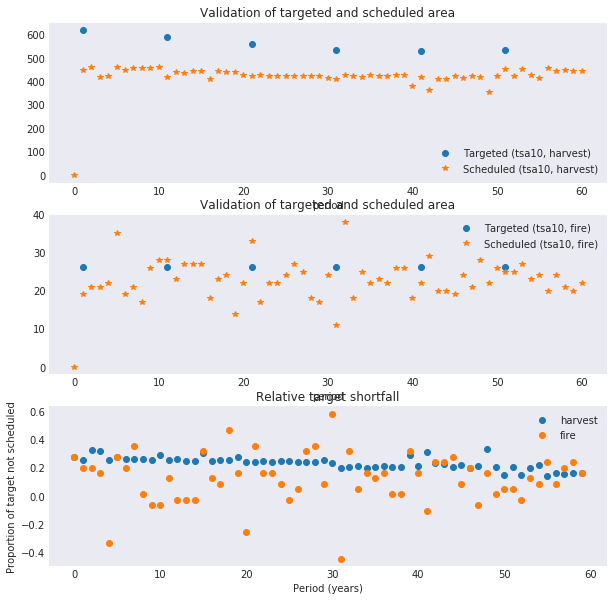

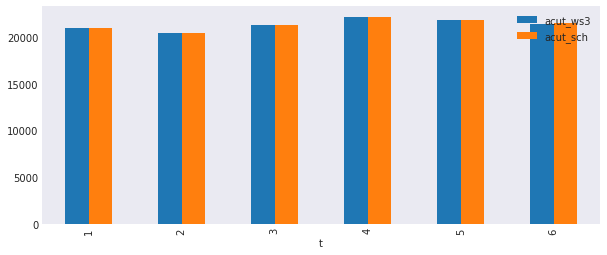

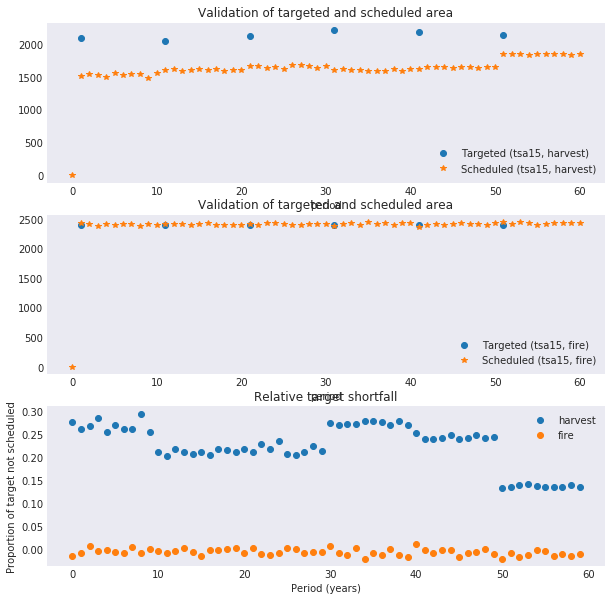

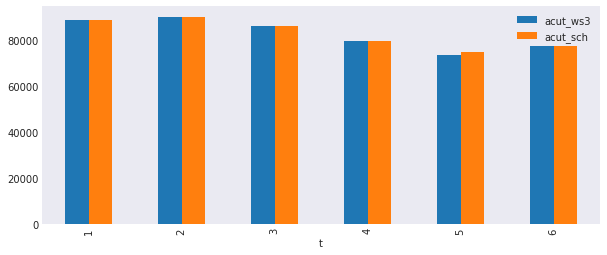

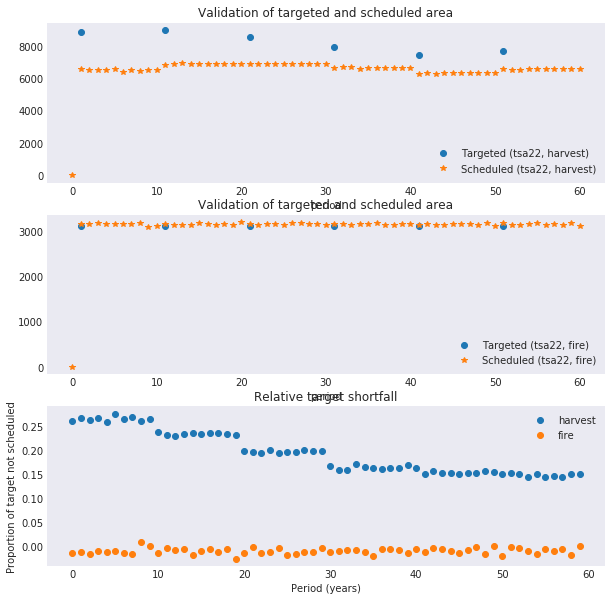

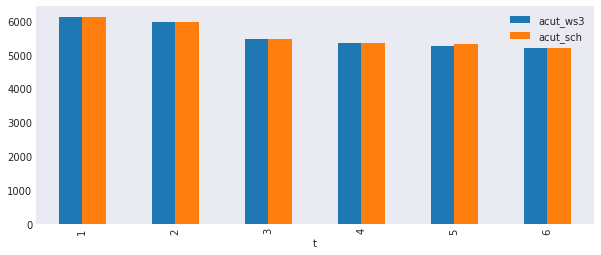

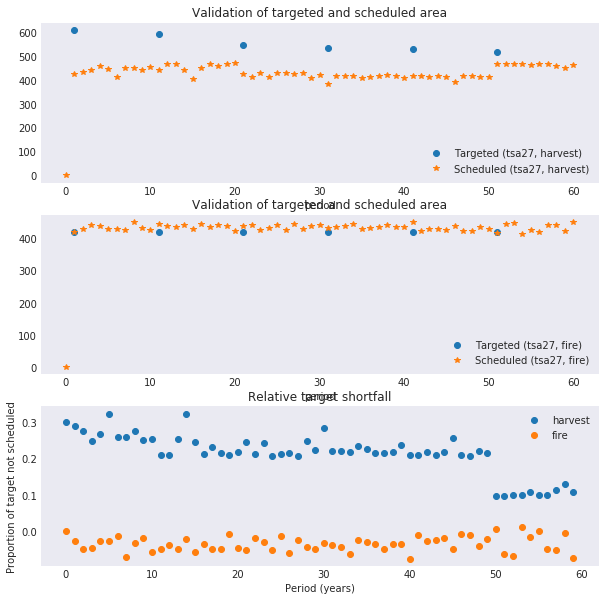

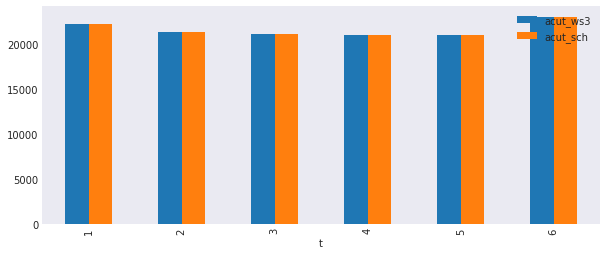

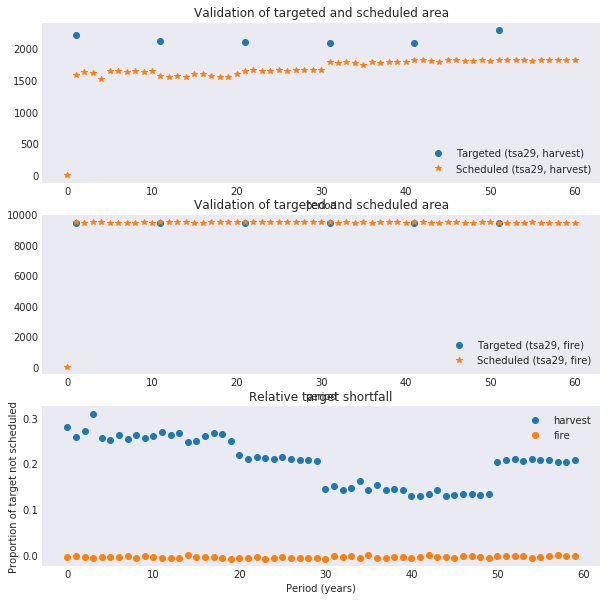

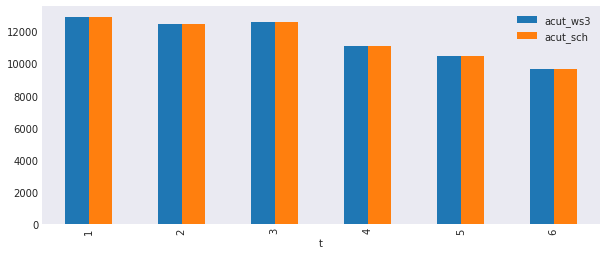

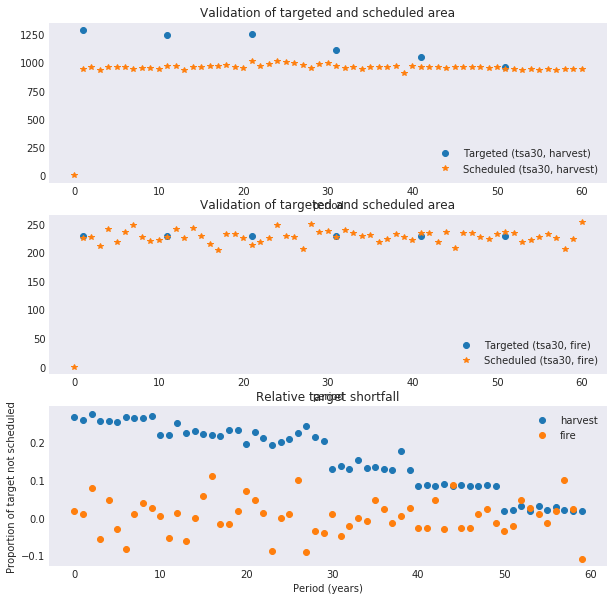

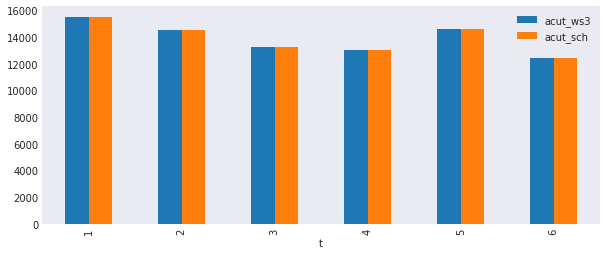

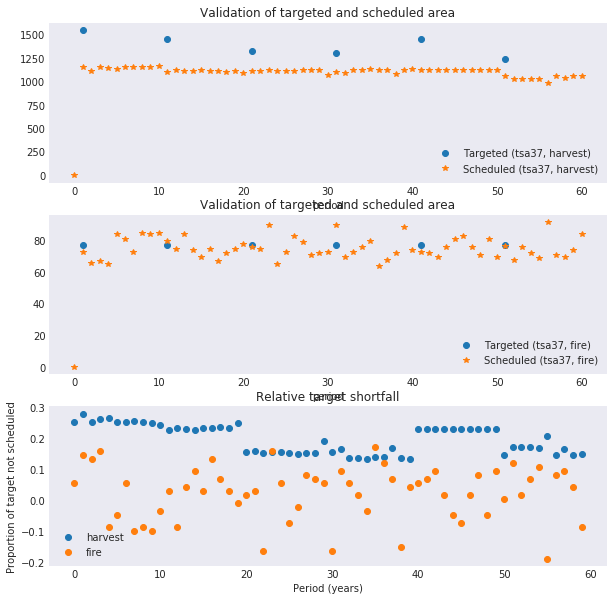

In [25]:
for i, bn in enumerate(basenames[:]):
    print(i, bn)
    fm, sch = amr_fm[i], amr_sch[i]
    fm.reset_actions()
    fm.initialize_areas()
    fm.apply_schedule(sch, compile_c_ycomps=True)
    deg_diagnostic1(fm, scenario_name, [bn], sch, util)
    deg_diagnostic2(fm, scenario_name, [bn], sch, tif_path, figsize=(10, 10))